Simple LR Coefficients: [1.06666667 1.00606061]
R² Score: 0.94


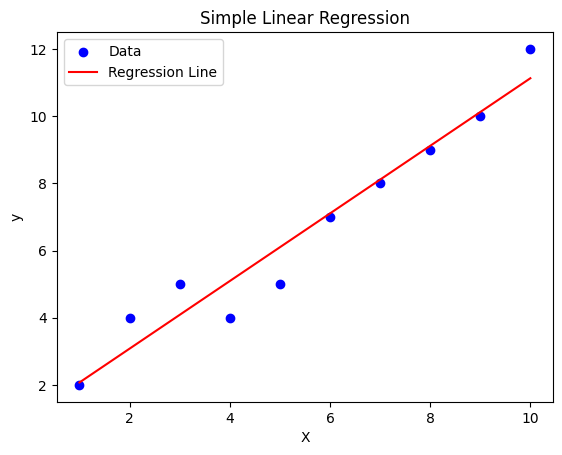

In [3]:
import numpy as np
import matplotlib.pyplot as plt


class SimpleLinearRegression:
    def __init__(self):
        self.coefficients_ = None
        self.intercept_ = None
        self.r2score_ = None
        self.y_pred_ = None

    def fit(self, X, y):
        n = len(X)
        X_b = np.c_[np.ones((n, 1)), X]
        self.coefficients_ = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
        self.intercept_ = self.coefficients_[0]
        y_pred = X_b.dot(self.coefficients_)
        self.r2score_ = 1 - (np.sum((y - y_pred) ** 2) /
                             np.sum((y - np.mean(y)) ** 2))
        self.y_pred_ = y_pred

    def predict(self, X):
        X_b = np.c_[np.ones((len(X), 1)), X]
        return X_b.dot(self.coefficients_)


X_simple = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10]).reshape(-1, 1)
y_simple = np.array([2, 4, 5, 4, 5, 7, 8, 9, 10, 12])

slr = SimpleLinearRegression()
slr.fit(X_simple, y_simple)

print(f"Simple LR Coefficients: {slr.coefficients_}")
print(f"R² Score: {slr.r2score_:.2f}")

plt.scatter(X_simple, y_simple, color='blue', label='Data')
plt.plot(X_simple, slr.y_pred_, color='red', label='Regression Line')
plt.title("Simple Linear Regression")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()

Multiple LR Coefficients: [-1.45333931  2.15806389  3.32011421]
R² Score: 0.95


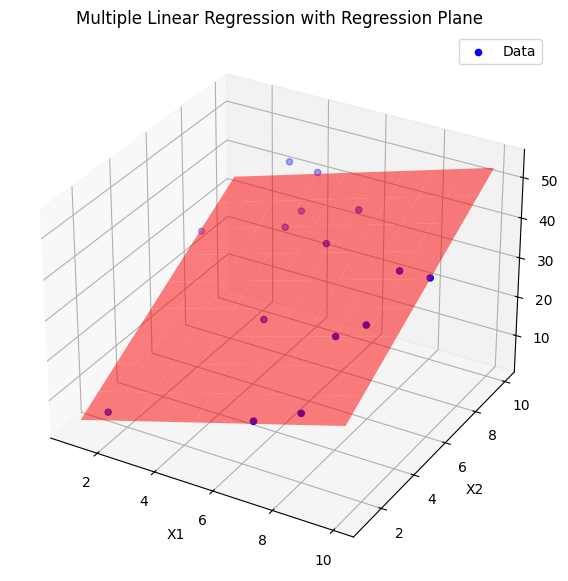

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

class MultipleLinearRegression:
    def __init__(self):
        self.coefficients_ = None
        self.intercept_ = None
        self.r2score_ = None

    def fit(self, X, y):
        n = X.shape[0]
        X_b = np.c_[np.ones((n,1)), X]
        self.coefficients_ = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
        self.intercept_ = self.coefficients_[0]
        y_pred = X_b.dot(self.coefficients_)
        self.r2score_ = 1 - (np.sum((y - y_pred)**2)/np.sum((y - np.mean(y))**2))
        self.y_pred_ = y_pred

    def predict(self, X):
        X_b = np.c_[np.ones((X.shape[0],1)), X]
        return X_b.dot(self.coefficients_)

np.random.seed(0)
X1 = np.random.randint(1, 11, 15)
X2 = np.random.randint(1, 11, 15)
X_multi = np.column_stack((X1, X2))
y_multi = 1 + 2*X1 + 3*X2 + np.random.randn(15)*2


mlr = MultipleLinearRegression()
mlr.fit(X_multi, y_multi)
print(f"Multiple LR Coefficients: {mlr.coefficients_}")
print(f"R² Score: {mlr.r2score_:.2f}")

fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(X_multi[:,0], X_multi[:,1], y_multi, color='blue', label='Data')

x1_surf, x2_surf = np.meshgrid(
    np.linspace(X_multi[:,0].min(), X_multi[:,0].max(), 10),
    np.linspace(X_multi[:,1].min(), X_multi[:,1].max(), 10)
)

pred_surf = mlr.predict(np.c_[x1_surf.ravel(), x2_surf.ravel()]).reshape(x1_surf.shape)

ax.plot_surface(x1_surf, x2_surf, pred_surf, color='red', alpha=0.5, rstride=1, cstride=1)

ax.set_xlabel('X1')
ax.set_ylabel('X2')
ax.set_zlabel('y')
ax.set_title("Multiple Linear Regression with Regression Plane")
ax.legend()
plt.show()

      Tv  Radio  Newspaper  Sales
1  230.1   37.8       69.2   22.1
2   44.5   39.3       45.1   10.4
3   17.2   45.9       69.3    9.3
4  151.5   41.3       58.5   18.5
5  180.8   10.8       58.4   12.9
Coefficients: [7.03259355 0.04753664]
Intercept   : 7.0326
Slope       : 0.0475
R² Score    : 0.6119


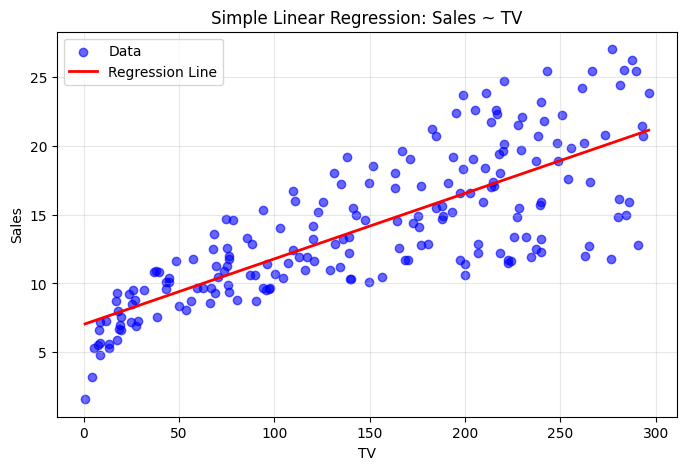

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


class SimpleLinearRegression:
    def __init__(self):
        self.coefficients_ = None
        self.intercept_ = None
        self.r2score_ = None
        self.y_pred_ = None

    def fit(self, X, y):
        X = np.asarray(X).reshape(-1, 1)
        y = np.asarray(y).reshape(-1)
        n = len(X)
        X_b = np.c_[np.ones((n, 1)), X]
        self.coefficients_ = np.linalg.lstsq(X_b, y, rcond=None)[0]
        self.intercept_ = self.coefficients_[0]
        y_pred = X_b.dot(self.coefficients_)
        self.r2score_ = 1 - (np.sum((y - y_pred) ** 2) /
                             np.sum((y - np.mean(y)) ** 2))
        self.y_pred_ = y_pred

    def predict(self, X):
        X = np.asarray(X).reshape(-1, 1)
        X_b = np.c_[np.ones((len(X), 1)), X]
        return X_b.dot(self.coefficients_)



URL = "https://www.statlearning.com/s/Advertising.csv"
df = pd.read_csv(URL, index_col=0)
df.columns = [c.strip().capitalize() for c in df.columns]   # chuẩn hóa tên cột
print(df.head())


X_simple = df["Tv"].values if "Tv" in df.columns else df["TV"].values
y_simple = df["Sales"].values

slr = SimpleLinearRegression()
slr.fit(X_simple, y_simple)

print(f"Coefficients: {slr.coefficients_}")
print(f"Intercept   : {slr.intercept_:.4f}")
print(f"Slope       : {slr.coefficients_[1]:.4f}")
print(f"R² Score    : {slr.r2score_:.4f}")


order = np.argsort(X_simple)
plt.figure(figsize=(8, 5))
plt.scatter(X_simple, y_simple, color='blue', alpha=0.6, label='Data')
plt.plot(X_simple[order], slr.y_pred_[order], color='red',
         linewidth=2, label='Regression Line')
plt.title("Simple Linear Regression: Sales ~ TV")
plt.xlabel("TV")
plt.ylabel("Sales")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

      Tv  Radio  Newspaper  Sales
1  230.1   37.8       69.2   22.1
2   44.5   39.3       45.1   10.4
3   17.2   45.9       69.3    9.3
4  151.5   41.3       58.5   18.5
5  180.8   10.8       58.4   12.9

=== Multiple Linear Regression ===
Intercept : 2.9389
Tv        : 0.0458
Radio     : 0.1885
Newspaper : -0.0010
R² Score  : 0.8972

=== sklearn (đối chiếu) ===
Intercept : 2.9389
Tv        : 0.0458
Radio     : 0.1885
Newspaper : -0.0010
R² Score  : 0.8972


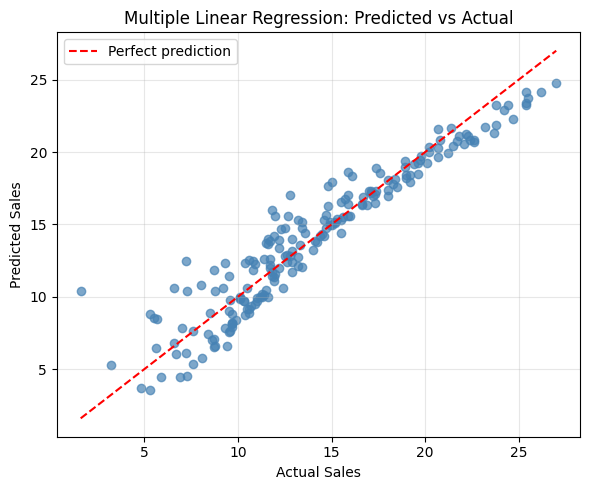

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


class MultipleLinearRegression:
    def __init__(self):
        self.coefficients_ = None
        self.intercept_ = None
        self.r2score_ = None
        self.y_pred_ = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()


        if X.ndim == 1:
            X = X.reshape(-1, 1)

        n = len(X)
        X_b = np.c_[np.ones((n, 1)), X]

        self.coefficients_ = np.linalg.lstsq(X_b, y, rcond=None)[0]
        self.intercept_ = self.coefficients_[0]

        y_pred = X_b.dot(self.coefficients_)
        ss_res = np.sum((y - y_pred) ** 2)
        ss_tot = np.sum((y - np.mean(y)) ** 2)
        self.r2score_ = 1 - ss_res / ss_tot
        self.y_pred_ = y_pred
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        X_b = np.c_[np.ones((len(X), 1)), X]
        return X_b.dot(self.coefficients_)


# ---------- 1. Load dữ liệu ----------
URL = "https://www.statlearning.com/s/Advertising.csv"
df = pd.read_csv(URL, index_col=0)
df.columns = [c.strip().capitalize() for c in df.columns]
# Đảm bảo tên cột: TV, Radio, Newspaper, Sales
print(df.head())

# ---------- 2. Chọn features & target ----------
feature_cols = ["Tv", "Radio", "Newspaper"]  # nếu lỗi, đổi thành ["TV", "Radio", "Newspaper"]
X_multi = df[feature_cols].values
y_multi = df["Sales"].values

# ---------- 3. Fit ----------
mlr = MultipleLinearRegression()
mlr.fit(X_multi, y_multi)

print("\n=== Multiple Linear Regression ===")
print(f"Intercept : {mlr.intercept_:.4f}")
for name, coef in zip(feature_cols, mlr.coefficients_[1:]):
    print(f"{name:<10}: {coef:.4f}")
print(f"R² Score  : {mlr.r2score_:.4f}")

# ---------- 4. So sánh với Simple LR ----------
from sklearn.linear_model import LinearRegression as SkLR  # (tùy chọn, để đối chiếu)

sk = SkLR().fit(X_multi, y_multi)
print("\n=== sklearn (đối chiếu) ===")
print(f"Intercept : {sk.intercept_:.4f}")
for name, coef in zip(feature_cols, sk.coef_):
    print(f"{name:<10}: {coef:.4f}")
print(f"R² Score  : {sk.score(X_multi, y_multi):.4f}")

# ---------- 5. Predicted vs Actual ----------
plt.figure(figsize=(6, 5))
plt.scatter(y_multi, mlr.y_pred_, color='steelblue', alpha=0.7)
lims = [min(y_multi.min(), mlr.y_pred_.min()),
        max(y_multi.max(), mlr.y_pred_.max())]
plt.plot(lims, lims, 'r--', label='Perfect prediction')
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Multiple Linear Regression: Predicted vs Actual")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Shape: (506, 14)
Columns: ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']

=== Simple LR (MEDV ~ RM) ===
Intercept : -34.6706
Slope     : 9.1021
R² Score  : 0.4835

=== Multiple LR (MEDV ~ all) ===
Intercept : 36.4595
CRIM      : -0.1080
ZN        :  0.0464
INDUS     :  0.0206
CHAS      :  2.6867
NOX       : -17.7666
RM        :  3.8099
AGE       :  0.0007
DIS       : -1.4756
RAD       :  0.3060
TAX       : -0.0123
PTRATIO   : -0.9527
B         :  0.0093
LSTAT     : -0.5248
R² Score  : 0.7406


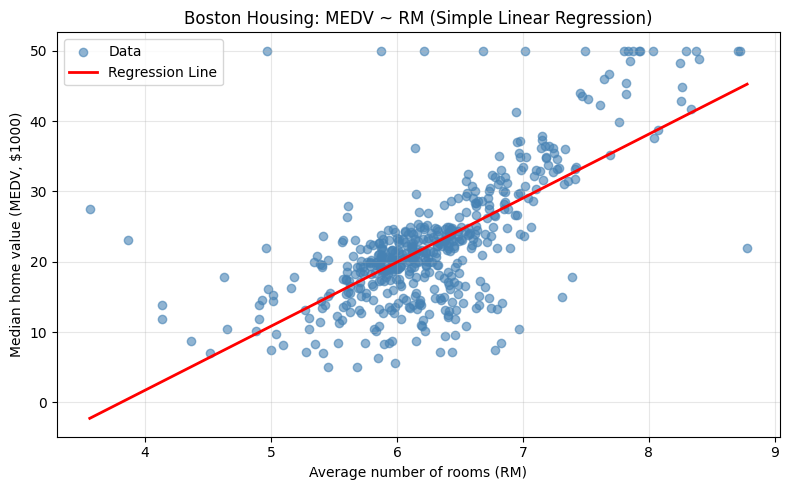

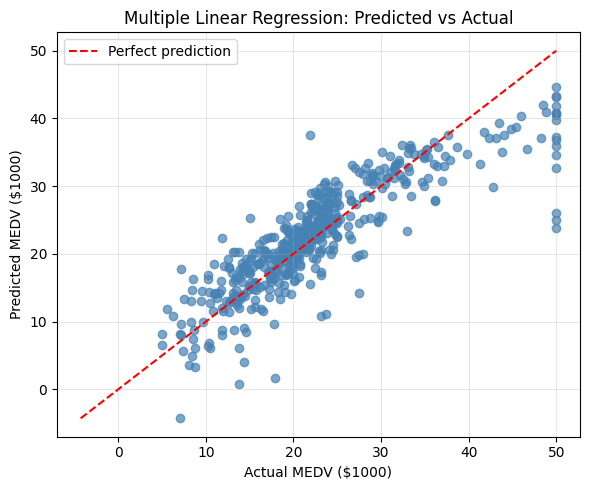

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ========== LOAD DỮ LIỆU ==========
URL = "https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv"
df = pd.read_csv(URL)
df.columns = [c.strip().upper() for c in df.columns]

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())


# ========== SIMPLE LINEAR REGRESSION ==========
class SimpleLinearRegression:
    def __init__(self):
        self.coefficients_ = None
        self.intercept_ = None
        self.r2score_ = None
        self.y_pred_ = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=float).reshape(-1, 1)
        y = np.asarray(y, dtype=float).ravel()
        n = len(X)
        X_b = np.c_[np.ones((n, 1)), X]
        self.coefficients_ = np.linalg.lstsq(X_b, y, rcond=None)[0]
        self.intercept_ = self.coefficients_[0]
        y_pred = X_b.dot(self.coefficients_)
        self.r2score_ = 1 - np.sum((y - y_pred)**2) / np.sum((y - y.mean())**2)
        self.y_pred_ = y_pred
        return self                    # ← ĐÃ THÊM

    def predict(self, X):
        X = np.asarray(X, dtype=float).reshape(-1, 1)
        X_b = np.c_[np.ones((len(X), 1)), X]
        return X_b.dot(self.coefficients_)


# ========== MULTIPLE LINEAR REGRESSION ==========
class MultipleLinearRegression:
    def __init__(self):
        self.coefficients_ = None
        self.intercept_ = None
        self.r2score_ = None
        self.y_pred_ = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        n = len(X)
        X_b = np.c_[np.ones((n, 1)), X]
        self.coefficients_ = np.linalg.lstsq(X_b, y, rcond=None)[0]
        self.intercept_ = self.coefficients_[0]
        y_pred = X_b.dot(self.coefficients_)
        self.r2score_ = 1 - np.sum((y - y_pred)**2) / np.sum((y - y.mean())**2)
        self.y_pred_ = y_pred
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        X_b = np.c_[np.ones((len(X), 1)), X]
        return X_b.dot(self.coefficients_)


# ========== FIT SIMPLE LR ==========
X_simple = df["RM"].values
y_simple = df["MEDV"].values

slr = SimpleLinearRegression()
slr.fit(X_simple, y_simple)

print("\n=== Simple LR (MEDV ~ RM) ===")
print(f"Intercept : {slr.intercept_:.4f}")
print(f"Slope     : {slr.coefficients_[1]:.4f}")
print(f"R² Score  : {slr.r2score_:.4f}")


# ========== FIT MULTIPLE LR ==========
feature_cols = [c for c in df.columns if c != "MEDV"]
X_multi = df[feature_cols].values
y_multi = df["MEDV"].values

mlr = MultipleLinearRegression()
mlr.fit(X_multi, y_multi)

print("\n=== Multiple LR (MEDV ~ all) ===")
print(f"Intercept : {mlr.intercept_:.4f}")
for name, coef in zip(feature_cols, mlr.coefficients_[1:]):
    print(f"{name:<10}: {coef: .4f}")
print(f"R² Score  : {mlr.r2score_:.4f}")


# ========== BIỂU ĐỒ 1: SIMPLE LR ==========
order = np.argsort(X_simple)
plt.figure(figsize=(8, 5))
plt.scatter(X_simple, y_simple, color="steelblue", alpha=0.6, label="Data")
plt.plot(X_simple[order], slr.y_pred_[order], color="red",
         linewidth=2, label="Regression Line")
plt.title("Boston Housing: MEDV ~ RM (Simple Linear Regression)")
plt.xlabel("Average number of rooms (RM)")
plt.ylabel("Median home value (MEDV, $1000)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# ========== BIỂU ĐỒ 2: MULTIPLE LR (Predicted vs Actual) ==========
plt.figure(figsize=(6, 5))
plt.scatter(y_multi, mlr.y_pred_, color="steelblue", alpha=0.7)
lims = [min(y_multi.min(), mlr.y_pred_.min()),
        max(y_multi.max(), mlr.y_pred_.max())]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual MEDV ($1000)")
plt.ylabel("Predicted MEDV ($1000)")
plt.title("Multiple Linear Regression: Predicted vs Actual")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()